# Onderdelen detecteren: alleen op het schaakbord (OpenCV)

**Opdracht:** automatische kandidaatdetectie zonder `labels/`, CNN, YOLO of handmatig gekozen objectlocaties. Alles buiten het schaakbord wordt genegeerd.

**Wat is nieuw?** De zwarte vakjes geven een eerste rasterschatting. Daarna controleren we of **een volledig raster van 8×11 vakjes** geometrisch én qua kleur overeenkomt met de foto. De bekende vakjesmiddens worden met een homografie rechtgetrokken. We segmenteren vervolgens uitsluitend in dat bordgebied.

**Status:** experimentele lokale GrabCut-verfijning, geen bewezen robuuste detector. De bounding boxes kunnen nog onvolledig zijn. Bij een onbetrouwbaar raster wordt de foto overgeslagen, niet alsnog een resultaat verzonnen. Classificatie volgt pas na betrouwbare detectie.

## 1. Afbeeldingen inladen

Plaats de afbeeldingen in `dataset/images/` of `images/`, of naast het notebook. Alleen JPG-bestanden worden geladen; `labels/` wordt nooit geopend.

In [44]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Zoek een map met foto's, zonder ooit labels te openen.
opties = [Path("dataset/images"), Path("images"), Path(".")]
MAP = next((p for p in opties if p.is_dir() and any(p.glob("*.jpg"))), None)
if MAP is None:
    raise FileNotFoundError("Geen JPG-foto's gevonden. Pas MAP aan.")

fotos = sorted(p for p in MAP.glob("*.jpg")
               if "leeg_schaakbord" not in p.stem.lower()
               and not p.stem.lower().startswith("prev_"))
print(f"Map: {MAP.resolve()}")
print(f"Aantal afbeeldingen: {len(fotos)}")

# Foto's worden verkleind om de verwerking redelijk snel te houden.
MAX_DIM = 1500

def lees_foto(pad):
    img = cv2.imread(str(pad))
    if img is None:
        raise ValueError(f"Kan afbeelding niet laden: {pad}")
    h, w = img.shape[:2]
    factor = min(1.0, MAX_DIM / max(h, w))
    return cv2.resize(img, None, fx=factor, fy=factor)


Map: C:\Users\Gkain\OneDrive\Documenten\PythonCrashCourse\computer vision\dataset\images
Aantal afbeeldingen: 240


## 2. Zwarte vakjes herkennen en een eerste raster fitten

We gebruiken alleen de pixels en contouren. Dit is nog geen objectdetectie.

In [45]:
def vind_zwarte_vakken(img):
    grijs = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    glad = cv2.GaussianBlur(grijs, (3, 3), 0)
    _, donker = cv2.threshold(
        glad, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )
    contouren, _ = cv2.findContours(
        donker, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE
    )
    kandidaten = []
    for contour in contouren:
        oppervlakte = cv2.contourArea(contour)
        if not 100 <= oppervlakte <= 6000:
            continue
        x, y, breedte, hoogte = cv2.boundingRect(contour)
        if min(breedte, hoogte) < 8:
            continue
        if max(breedte, hoogte) / min(breedte, hoogte) > 1.5:
            continue
        if oppervlakte / (breedte * hoogte) < 0.58:
            continue
        poly = cv2.approxPolyDP(
            contour, 0.065 * cv2.arcLength(contour, True), True
        )
        if not 4 <= len(poly) <= 6:
            continue
        # Een witte binnencontour telt niet als zwart vakje.
        cx = int(np.clip(x + breedte // 2, 0, grijs.shape[1] - 1))
        cy = int(np.clip(y + hoogte // 2, 0, grijs.shape[0] - 1))
        if donker[cy, cx] == 0:
            continue
        rechthoek = cv2.minAreaRect(contour)
        kandidaten.append((np.array(rechthoek[0]), oppervlakte, rechthoek))

    if len(kandidaten) < 6:
        raise ValueError("Te weinig zwarte vierkanten gevonden")
    oppervlaktes = np.array([c[1] for c in kandidaten])
    normaal = np.median(oppervlaktes)
    kandidaten = [c for c in kandidaten
                  if 0.55 * normaal < c[1] < 1.75 * normaal]
    if len(kandidaten) < 6:
        raise ValueError("Te weinig vierkanten met vergelijkbare grootte")
    return kandidaten


def pas_raster(kandidaten):
    posities = np.array([c[0] for c in kandidaten])
    vakgrootte = float(np.sqrt(np.median([c[1] for c in kandidaten])))

    # Een vierkant is bij 0 en 90 graden dezelfde vorm.
    hoeken = np.array([(c[2][2] + 45) % 90 - 45 for c in kandidaten])
    theta = np.deg2rad(float(np.median(hoeken)))
    u = vakgrootte * np.array([np.cos(theta), np.sin(theta)])
    v = vakgrootte * np.array([-np.sin(theta), np.cos(theta)])
    basis = np.column_stack([u, v])
    inverse = np.linalg.inv(basis)

    beste = None
    for anker in posities:
        indices = np.rint((posities - anker) @ inverse.T).astype(int)
        voorspeld = anker + indices @ basis.T
        fouten = np.linalg.norm(posities - voorspeld, axis=1)
        # Zwarte vakjes liggen op dezelfde pariteit van het schaakbord.
        inliers = ((fouten < 0.26 * vakgrootte)
                   & ((indices[:, 0] + indices[:, 1]) % 2 == 0))
        score = np.sum(inliers * (1 - np.minimum(fouten / vakgrootte, 1)))
        if beste is None or score > beste[0]:
            beste = (score, anker, indices, inliers)

    _, anker, indices, inliers = beste
    if inliers.sum() < 6:
        raise ValueError("Raster onbetrouwbaar: onvoldoende overeenkomende vakjes")

    # Kleine aanpassing van de rasterafstand en verschuiving.
    trans = np.array([anker, u, v], dtype=float)
    for _ in range(4):
        A = np.column_stack([np.ones(inliers.sum()), indices[inliers]])
        kandidaat_trans = np.linalg.lstsq(A, posities[inliers], rcond=None)[0]
        nu, nv = kandidaat_trans[1], kandidaat_trans[2]
        if not (0.80 * vakgrootte < np.linalg.norm(nu) < 1.20 * vakgrootte
                and 0.80 * vakgrootte < np.linalg.norm(nv) < 1.20 * vakgrootte):
            break
        basis_nieuw = np.column_stack([kandidaat_trans[1], kandidaat_trans[2]])
        indices_nieuw = np.rint(
            (posities - kandidaat_trans[0]) @ np.linalg.inv(basis_nieuw).T
        ).astype(int)
        fouten = np.linalg.norm(
            posities - (kandidaat_trans[0] + indices_nieuw @ basis_nieuw.T),
            axis=1
        )
        inliers_nieuw = ((fouten < 0.22 * vakgrootte)
                        & ((indices_nieuw[:, 0] + indices_nieuw[:, 1]) % 2 == 0))
        if inliers_nieuw.sum() < 6:
            break  # Houd vorige, betrouwbaardere schatting.
        trans, indices, inliers = kandidaat_trans, indices_nieuw, inliers_nieuw

    # Affiene projectie van rastercoördinaten naar de foto.
    M = np.array([[trans[1, 0], trans[2, 0], trans[0, 0]],
                  [trans[1, 1], trans[2, 1], trans[0, 1]],
                  [0., 0., 1.]], dtype=np.float64)

    return M, indices[inliers], inliers, vakgrootte


## 3. Volledig schaakbord lokaliseren en controleren

We zoeken een rechthoekig raster van **8×11 of 11×8 vakjes**. Kandidaten die op zwart plakband of losse voorwerpen lijken, mogen geen aanleiding zijn om het bord buiten zijn echte grenzen te plaatsen. De code controleert daarom de verwachte zwart-witverdeling en geeft een foutmelding als de rastercontrole onvoldoende is.

In [46]:
def selecteer_bord(img, kandidaten, M, vakgrootte):
    k = kandidaten
    v = vakgrootte
    h,w=img.shape[:2]
    centers=np.array([a[0] for a in k],dtype=np.float32)
    uv=cv2.perspectiveTransform(centers.reshape(-1,1,2),np.linalg.inv(M)).reshape(-1,2)
    ind=np.rint(uv).astype(int)
    reconstructed=cv2.perspectiveTransform(ind.reshape(-1,1,2).astype(np.float32),M).reshape(-1,2)
    err=np.linalg.norm(reconstructed-centers,axis=1)
    valid=(err < .28*v) & ((ind.sum(axis=1)%2)==0)
    inlier_idx=ind[valid]
    if len(inlier_idx)<8:raise ValueError('Minder dan 8 betrouwbare zwarte vakjes')
    gray=cv2.cvtColor(img,cv2.COLOR_BGR2GRAY)
    variants=[]
    span=np.ptp(inlier_idx,axis=0)
    for cols,rows in [(8,11),(11,8)]:
       # all possible [x0..x0+cols-1] include a substantial portion of known candidates
       for x0 in range(int(inlier_idx[:,0].min()-cols+2),int(inlier_idx[:,0].max())):
        for y0 in range(int(inlier_idx[:,1].min()-rows+2),int(inlier_idx[:,1].max())):
         xi=np.arange(x0,x0+cols)
         yi=np.arange(y0,y0+rows)
         uu,vv=np.meshgrid(xi,yi)
         tilegrid=np.stack([uu.ravel(),vv.ravel()],axis=-1).astype('float32')
         pix=cv2.perspectiveTransform(tilegrid.reshape(-1,1,2),M).reshape(-1,2)
         xs=np.rint(pix[:,0]).astype(int);ys=np.rint(pix[:,1]).astype(int)
         inside=(xs>8)&(ys>8)&(xs<w-8)&(ys<h-8)
         if inside.mean()<.95:continue
         # check color polarization with global Otsu? detect dark squares vs white paper on board. use fixed medians from candidate black squares and nearby one-away whites
         patchvals=np.zeros(len(xs),float)
         for j0,(x,y) in enumerate(zip(xs,ys)):
          if inside[j0]:
           patchvals[j0]=np.median(gray[y-4:y+5,x-4:x+5])
         dark_expected=((tilegrid[:,0]+tilegrid[:,1])%2)==0
         black=patchvals[dark_expected&inside];white=patchvals[(~dark_expected)&inside]
         if len(black)<20 or len(white)<20:continue
         bc=np.median(black);wc=np.median(white)
         contrast=wc-bc
         if contrast<65:continue
         t=(bc+wc)/2
         correct=((dark_expected & (patchvals<t)) | ((~dark_expected)&(patchvals>=t))) & inside
         # robust standardized signed contrast + regularity
         score=np.mean(correct)*contrast + (correct.mean()-.5)*40
         # from inliers fraction in region
         within=((inlier_idx[:,0]>=x0)&(inlier_idx[:,0]<x0+cols)&(inlier_idx[:,1]>=y0)&(inlier_idx[:,1]<y0+rows))
         cnt=within.sum()
         score+=min(cnt,40)*.2
         variants.append((score,cols,rows,x0,y0,correct.mean(),contrast,cnt))
    if not variants:raise ValueError('Geen volledige bordregio met duidelijk zwart-wit patroon')
    result=max(variants)
    _,cols,rows,x0,y0,acc,contrast,cnt=result
    if acc<.79:raise ValueError(f'Schaakbordpatroon niet betrouwbaar ({acc:.0%} overeenstemming)')
    # refine H using known black squares WITHIN chosen region
    within=valid&(ind[:,0]>=x0)&(ind[:,0]<x0+cols)&(ind[:,1]>=y0)&(ind[:,1]<y0+rows)
    if within.sum()<8:raise ValueError('Te weinig punten binnen schaakbord')
    H,mask=cv2.findHomography(ind[within].astype(np.float32),centers[within],cv2.RANSAC,3.0)
    if H is None:raise ValueError('Homografie mislukt')
    meanerr=np.median(np.linalg.norm(cv2.perspectiveTransform(ind[within].reshape(-1,1,2).astype('float32'),H).reshape(-1,2)-centers[within],axis=1))
    return H,(cols,rows,x0,y0,acc,contrast,cnt,meanerr),inlier_idx

## 4. Objecten op het bord detecteren en lokaal verfijnen

De bordselectie, homografie en achtergrondschatting blijven hetzelfde. Het verschilmasker levert **automatische startpunten**; `cv2.grabCut` probeert vervolgens de volledige buitencontour rondom die punten te reconstrueren. Er worden **geen labels** gebruikt. Het oorspronkelijke masker blijft als `mask_zaad` beschikbaar om fouten zichtbaar te maken.

**Beperking:** objecten zonder startpunt worden niet alsnog gevonden. Ook kunnen lange objecten in meerdere contouren uiteenvallen en kunnen nabije objecten samensmelten.

In [47]:
import cv2,numpy as np

def verfijn_met_grabcut(bord, zaad, score, cell=52):
    h,w=zaad.shape
    seed=(zaad>0).astype(np.uint8)*255
    kern=lambda n:cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(n,n))
    grouped=cv2.dilate(seed,kern(23),iterations=1)
    n,labels,stats,_=cv2.connectedComponentsWithStats(grouped,8)
    resultaat=np.zeros_like(seed)
    reports=[]
    for i in range(1,n):
        gx,gy,gw,gh,ga=map(int,stats[i])
        basis=np.zeros_like(seed)
        basis[labels==i]=seed[labels==i]
        if cv2.countNonZero(basis)<18:continue
        # skip long board-edge artifacts, giant merged regions
        if ga>0.20*h*w:continue
        # bounding of region + 1 tile extra context
        margin=max(20,int(0.65*cell))
        xa=max(0,gx-margin);ya=max(0,gy-margin)
        xb=min(w,gx+gw+margin);yb=min(h,gy+gh+margin)
        cut=bord[ya:yb,xa:xb]
        sh,sw=cut.shape[:2]
        seeds=basis[ya:yb,xa:xb]
        scorecut=score[ya:yb,xa:xb]
        definite=cv2.erode(seeds,kern(3),iterations=1)
        if cv2.countNonZero(definite)<5: definite=seeds
        # initialize with probable foreground around core only
        gc=np.full((sh,sw),cv2.GC_PR_BGD,np.uint8)
        probable=cv2.dilate(seeds,kern(31),iterations=1)
        gc[(probable>0) & (scorecut>12)]=cv2.GC_PR_FGD
        gc[definite>0]=cv2.GC_FGD
        # background from far away and ROI border
        far=cv2.dilate(probable,kern(25),iterations=1)==0
        gc[far]=cv2.GC_BGD
        gc[:3,:]=cv2.GC_BGD; gc[-3:,:]=cv2.GC_BGD
        gc[:,:3]=cv2.GC_BGD; gc[:,-3:]=cv2.GC_BGD
        if not (np.any(gc==cv2.GC_BGD) and np.any(gc==cv2.GC_FGD)):continue
        try:
            bg=np.zeros((1,65),np.float64);fg=np.zeros((1,65),np.float64)
            cv2.grabCut(cut,gc,None,bg,fg,4,cv2.GC_INIT_WITH_MASK)
        except cv2.error:continue
        mask=np.uint8((gc==cv2.GC_FGD)|(gc==cv2.GC_PR_FGD))*255
        mask=cv2.morphologyEx(mask,cv2.MORPH_OPEN,kern(3))
        mask=cv2.morphologyEx(mask,cv2.MORPH_CLOSE,kern(7))
        nc,lab,st,_=cv2.connectedComponentsWithStats(mask,8)
        for j in range(1,nc):
            ymask=(lab==j)
            overlap=np.count_nonzero(ymask & (seeds>0))
            if overlap<max(8,0.12*cv2.countNonZero(seeds)):
                continue
            if st[j,cv2.CC_STAT_AREA] > 0.65*sh*sw:continue
            # enforce original solid area stays inside
            result=mask[ymask] if False else None
            patch=resultaat[ya:yb,xa:xb]
            patch[ymask]=255
            reports.append((i,j,overlap,st[j,cv2.CC_STAT_AREA]))
    return resultaat,reports



# Verbeterde alternatieve schaakborddetectie
# Vervangt de oude vind_bord_sb()

def vind_bord_sb(img, cell=52):

    grijs = cv2.cvtColor(
        img, cv2.COLOR_BGR2GRAY
    )

    # ==========================================
    # 1. VERSCHILLENDE VOORBEWERKINGEN
    # ==========================================

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    contrast = clahe.apply(grijs)

    # Verschillende beeldversies proberen
    varianten = [
        (grijs, 1.0, "Origineel"),
        (contrast, 1.0, "CLAHE")
    ]

    # Verkleinde versie toevoegen bij grote foto's
    max_zijde = max(grijs.shape)

    if max_zijde > 1600:

        schaal = 1600 / max_zijde

        klein = cv2.resize(
            grijs,
            None,
            fx=schaal,
            fy=schaal,
            interpolation=cv2.INTER_AREA
        )

        klein_contrast = clahe.apply(klein)

        varianten.extend([
            (klein, schaal, "Verkleind"),
            (klein_contrast, schaal, "Verkleind + CLAHE")
        ])

    # ==========================================
    # 2. SCHAAKBORDHOEKEN ZOEKEN
    # ==========================================

    for afbeelding, schaal, naam in varianten:

        for cols, rows in [(7, 10), (10, 7)]:

            gevonden, hoeken = cv2.findChessboardCornersSB(
                afbeelding,
                (cols, rows),
                flags=cv2.CALIB_CB_EXHAUSTIVE
            )

            if not gevonden:
                continue

            # Punten naar originele foto terugrekenen
            bron = (
                hoeken.reshape(-1, 2) / schaal
            ).astype(np.float32)

            doel = np.float32([
                [(x + 1) * cell, (y + 1) * cell]
                for y in range(rows)
                for x in range(cols)
            ])

            # ==================================
            # 3. PERSPECTIEFCORRECTIE
            # ==================================

            H, inliers = cv2.findHomography(
                bron,
                doel,
                cv2.RANSAC,
                3.0
            )

            if H is None or inliers is None:
                continue

            betrouwbaarheid = float(np.mean(inliers))

            if betrouwbaarheid < 0.85:
                continue

            breedte = (cols + 1) * cell
            hoogte = (rows + 1) * cell

            # ==================================
            # 4. CONTROLE OP GELDIGE PIXELS
            # ==================================

            dekking = cv2.warpPerspective(
                np.full(grijs.shape, 255, dtype=np.uint8),
                H,
                (breedte, hoogte)
            )

            if np.mean(dekking > 0) < 0.95:
                continue

            bord = cv2.warpPerspective(
                img,
                H,
                (breedte, hoogte)
            )

            # Controleer het gevonden raster:
            # zwarte en witte vakjes moeten
            # afwisselende helderheden hebben.
            bord_grijs = cv2.cvtColor(
                bord, cv2.COLOR_BGR2GRAY
            )

            waarden = []

            for y in range(rows + 1):
                for x in range(cols + 1):

                    cx = int((x + 0.5) * cell)
                    cy = int((y + 0.5) * cell)

                    waarde = bord_grijs[cy, cx]

                    waarden.append((
                        (x + y) % 2,
                        float(waarde)
                    ))

            even = [v for p, v in waarden if p == 0]
            oneven = [v for p, v in waarden if p == 1]

            contrast_raster = abs(
                np.median(even) - np.median(oneven)
            )

            if contrast_raster < 25:
                continue

            print(
                f"ChessboardCornersSB: {naam}, "
                f"{betrouwbaarheid:.0%} inliers, "
                f"rastercontrast {contrast_raster:.1f}"
            )

            return bord, np.linalg.inv(H), betrouwbaarheid

    raise ValueError(
        "Beide schaakbordmethoden mislukt"
    )




def detecteer_op_bord(img):

    cell = 52
    methode = "Zwarte vakjes"

    # ==========================================
    # 1. SCHAAKBORD HERKENNEN
    # ==========================================

    try:
        k = vind_zwarte_vakken(img)
        M, idx, inl, v = pas_raster(k)

        H, detail, ind = selecteer_bord(
            img, k, M, v
        )

        cols, rows, x0, y0, acc, contrast, cnt, meanerr = detail

        t = np.array([
            [1/cell, 0, x0 - 0.5],
            [0, 1/cell, y0 - 0.5],
            [0, 0, 1]
        ], dtype=np.float64)

        output2orig = H @ t

        bord = cv2.warpPerspective(
            img,
            np.linalg.inv(output2orig),
            (cols * cell, rows * cell)
        )

        fase = (x0 + y0) % 2

    except (ValueError, RuntimeError, cv2.error):

        bord, output2orig, acc = vind_bord_sb(img, cell)

        methode = "ChessboardCornersSB"
        meanerr = np.nan

        cols = bord.shape[1] // cell
        rows = bord.shape[0] // cell

        # Kleurvolgorde van het raster bepalen
        grijs = cv2.cvtColor(bord, cv2.COLOR_BGR2GRAY)

        even = []
        oneven = []

        for y in range(rows):
            for x in range(cols):

                vak = grijs[
                    y*cell+15:y*cell+cell-15,
                    x*cell+15:x*cell+cell-15
                ]

                waarde = np.median(vak)

                if (x + y) % 2 == 0:
                    even.append(waarde)
                else:
                    oneven.append(waarde)

        fase = 0 if np.median(even) < np.median(oneven) else 1

        H = output2orig
        detail = None

    # ==========================================
    # 2. ACHTERGRONDMODEL
    # ==========================================

    h, w = bord.shape[:2]

    lab = cv2.cvtColor(
        bord, cv2.COLOR_BGR2LAB
    ).astype(np.float32)

    YY, XX = np.indices((h, w))

    iu = XX // cell
    iv = YY // cell

    parity = ((iu + iv + fase) % 2 == 0)

    safe = (
        (np.minimum(XX % cell, cell-1-XX % cell) > 9)
        &
        (np.minimum(YY % cell, cell-1-YY % cell) > 9)
    )

    cblack = np.median(lab[safe & parity], axis=0)
    cwhite = np.median(lab[safe & ~parity], axis=0)

    model = np.where(
        parity[:, :, None],
        cblack,
        cwhite
    )

    bg_err = cv2.GaussianBlur(
        lab[:, :, 0] - model[:, :, 0],
        (0, 0),
        cell * 1.4
    )

    model[:, :, 0] += np.clip(bg_err, -15, 15)

    # ==========================================
    # 3. VERSCHILMASKER
    # ==========================================

    delta = np.abs(lab - model)

    score = (
        0.5 * delta[:, :, 0]
        + 0.25 * delta[:, :, 1]
        + 0.25 * delta[:, :, 2]
    )

    vals = score[safe]

    med = np.median(vals)
    mad = np.median(np.abs(vals - med))

    thr = max(30, med + 5 * 1.4826 * mad)


    # Kleinere marge rond de rasterlijnen
    marge = 3

    binnen = (
        (np.minimum(XX % cell, cell - 1 - XX % cell) > marge)
        &
        (np.minimum(YY % cell, cell - 1 - YY % cell) > marge)
    )

    # Objectmasker met minder onderbrekingen
    mask = np.uint8(
        (score > thr) & binnen
    ) * 255


    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (3, 3)
    )

    mask = cv2.morphologyEx(
        mask, cv2.MORPH_OPEN, kernel
    )

    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (17, 17)
    )

    mask = cv2.morphologyEx(
        mask, cv2.MORPH_CLOSE, kernel
    )

    mask_zaad = mask.copy()

    # ==========================================
    # 4. GRABCUT
    # ==========================================

    mask_verfijnd, _ = verfijn_met_grabcut(
        bord, mask_zaad, score, cell
    )

    if cv2.countNonZero(mask_verfijnd) > 0:
        mask = mask_verfijnd
        status = "GrabCut toegepast"
    else:
        status = "Geen GrabCut-contour; zaadmasker behouden"

    # ==========================================
    # 5. OBJECTDETECTIE
    # ==========================================

    count, labels, stats, _ = (
        cv2.connectedComponentsWithStats(mask, 8)
    )

    detections = []

    display = bord.copy()
    volledig = img.copy()

    for i in range(1, count):

        x, y, bw, bh, area = map(int, stats[i])

        if area < 80 or min(bw, bh) < 8:
            continue

        if area > 0.1 * w * h:
            continue

        detections.append((x, y, bw, bh, area))

        cv2.rectangle(
            display,
            (x, y),
            (x+bw, y+bh),
            (0, 255, 0),
            2
        )

        # Detectie terugprojecteren op originele foto
        hoeken = np.float32([
            [x, y],
            [x+bw, y],
            [x+bw, y+bh],
            [x, y+bh]
        ]).reshape(-1, 1, 2)

        origineel = cv2.perspectiveTransform(
            hoeken, output2orig
        )

        cv2.polylines(
            volledig,
            [np.rint(origineel).astype(np.int32)],
            True,
            (0, 255, 0),
            2
        )

    # ==========================================
    # 6. SCHAAKBORDGRENS TEKENEN
    # ==========================================

    bordhoeken = np.float32([
        [0, 0],
        [w-1, 0],
        [w-1, h-1],
        [0, h-1]
    ]).reshape(-1, 1, 2)

    hoekjes = cv2.perspectiveTransform(
        bordhoeken, output2orig
    )

    cv2.polylines(
        volledig,
        [np.rint(hoekjes).astype(np.int32)],
        True,
        (255, 0, 255),
        2
    )

    return {
        "board": bord,
        "model": cv2.cvtColor(
            np.uint8(np.clip(model, 0, 255)),
            cv2.COLOR_LAB2BGR
        ),
        "mask": mask,
        "mask_zaad": mask_zaad,
        "verfijning": status,
        "res": display,
        "origineel": volledig,
        "details": detail,
        "detections": detections,
        "H": H,
        "overeenkomst": acc,
        "reprojectiefout": meanerr,
        "methode": methode
    }


## 5. Test op willekeurige foto's

Probeer maximaal 30 willekeurig gekozen foto's en toon de eerste vijf waarvoor de bordcontrole slaagt. Vergelijk **Oorspronkelijk masker** met **GrabCut-masker** en controleer of de volledige objectvorm tevoorschijn komt. Foto's die de bordcontrole niet halen blijven uitgesloten. De labels-map wordt nergens geopend.

ChessboardCornersSB: Origineel, 99% inliers, rastercontrast 142.5
20261106_133323_v_flip.jpg: ChessboardCornersSB — 99% overeenkomst — 1 kandidaten
20261106_132207.jpg: overgeslagen — Beide schaakbordmethoden mislukt
ChessboardCornersSB: Origineel, 100% inliers, rastercontrast 120.5
20261106_132043_hv_flip.jpg: ChessboardCornersSB — 100% overeenkomst — 1 kandidaten
ChessboardCornersSB: Origineel, 100% inliers, rastercontrast 146.0
20261106_133446_h_flip.jpg: ChessboardCornersSB — 100% overeenkomst — 1 kandidaten
20261106_132358_hv_flip.jpg: overgeslagen — Beide schaakbordmethoden mislukt
20261106_132352_hv_flip.jpg: overgeslagen — Beide schaakbordmethoden mislukt
20261106_132301_h_flip.jpg: overgeslagen — Beide schaakbordmethoden mislukt
20261106_132209_v_flip.jpg: overgeslagen — Beide schaakbordmethoden mislukt
ChessboardCornersSB: Origineel, 100% inliers, rastercontrast 145.0
20261106_133446.jpg: ChessboardCornersSB — 100% overeenkomst — 1 kandidaten
20261106_132206_hv_flip.jpg: Zwar

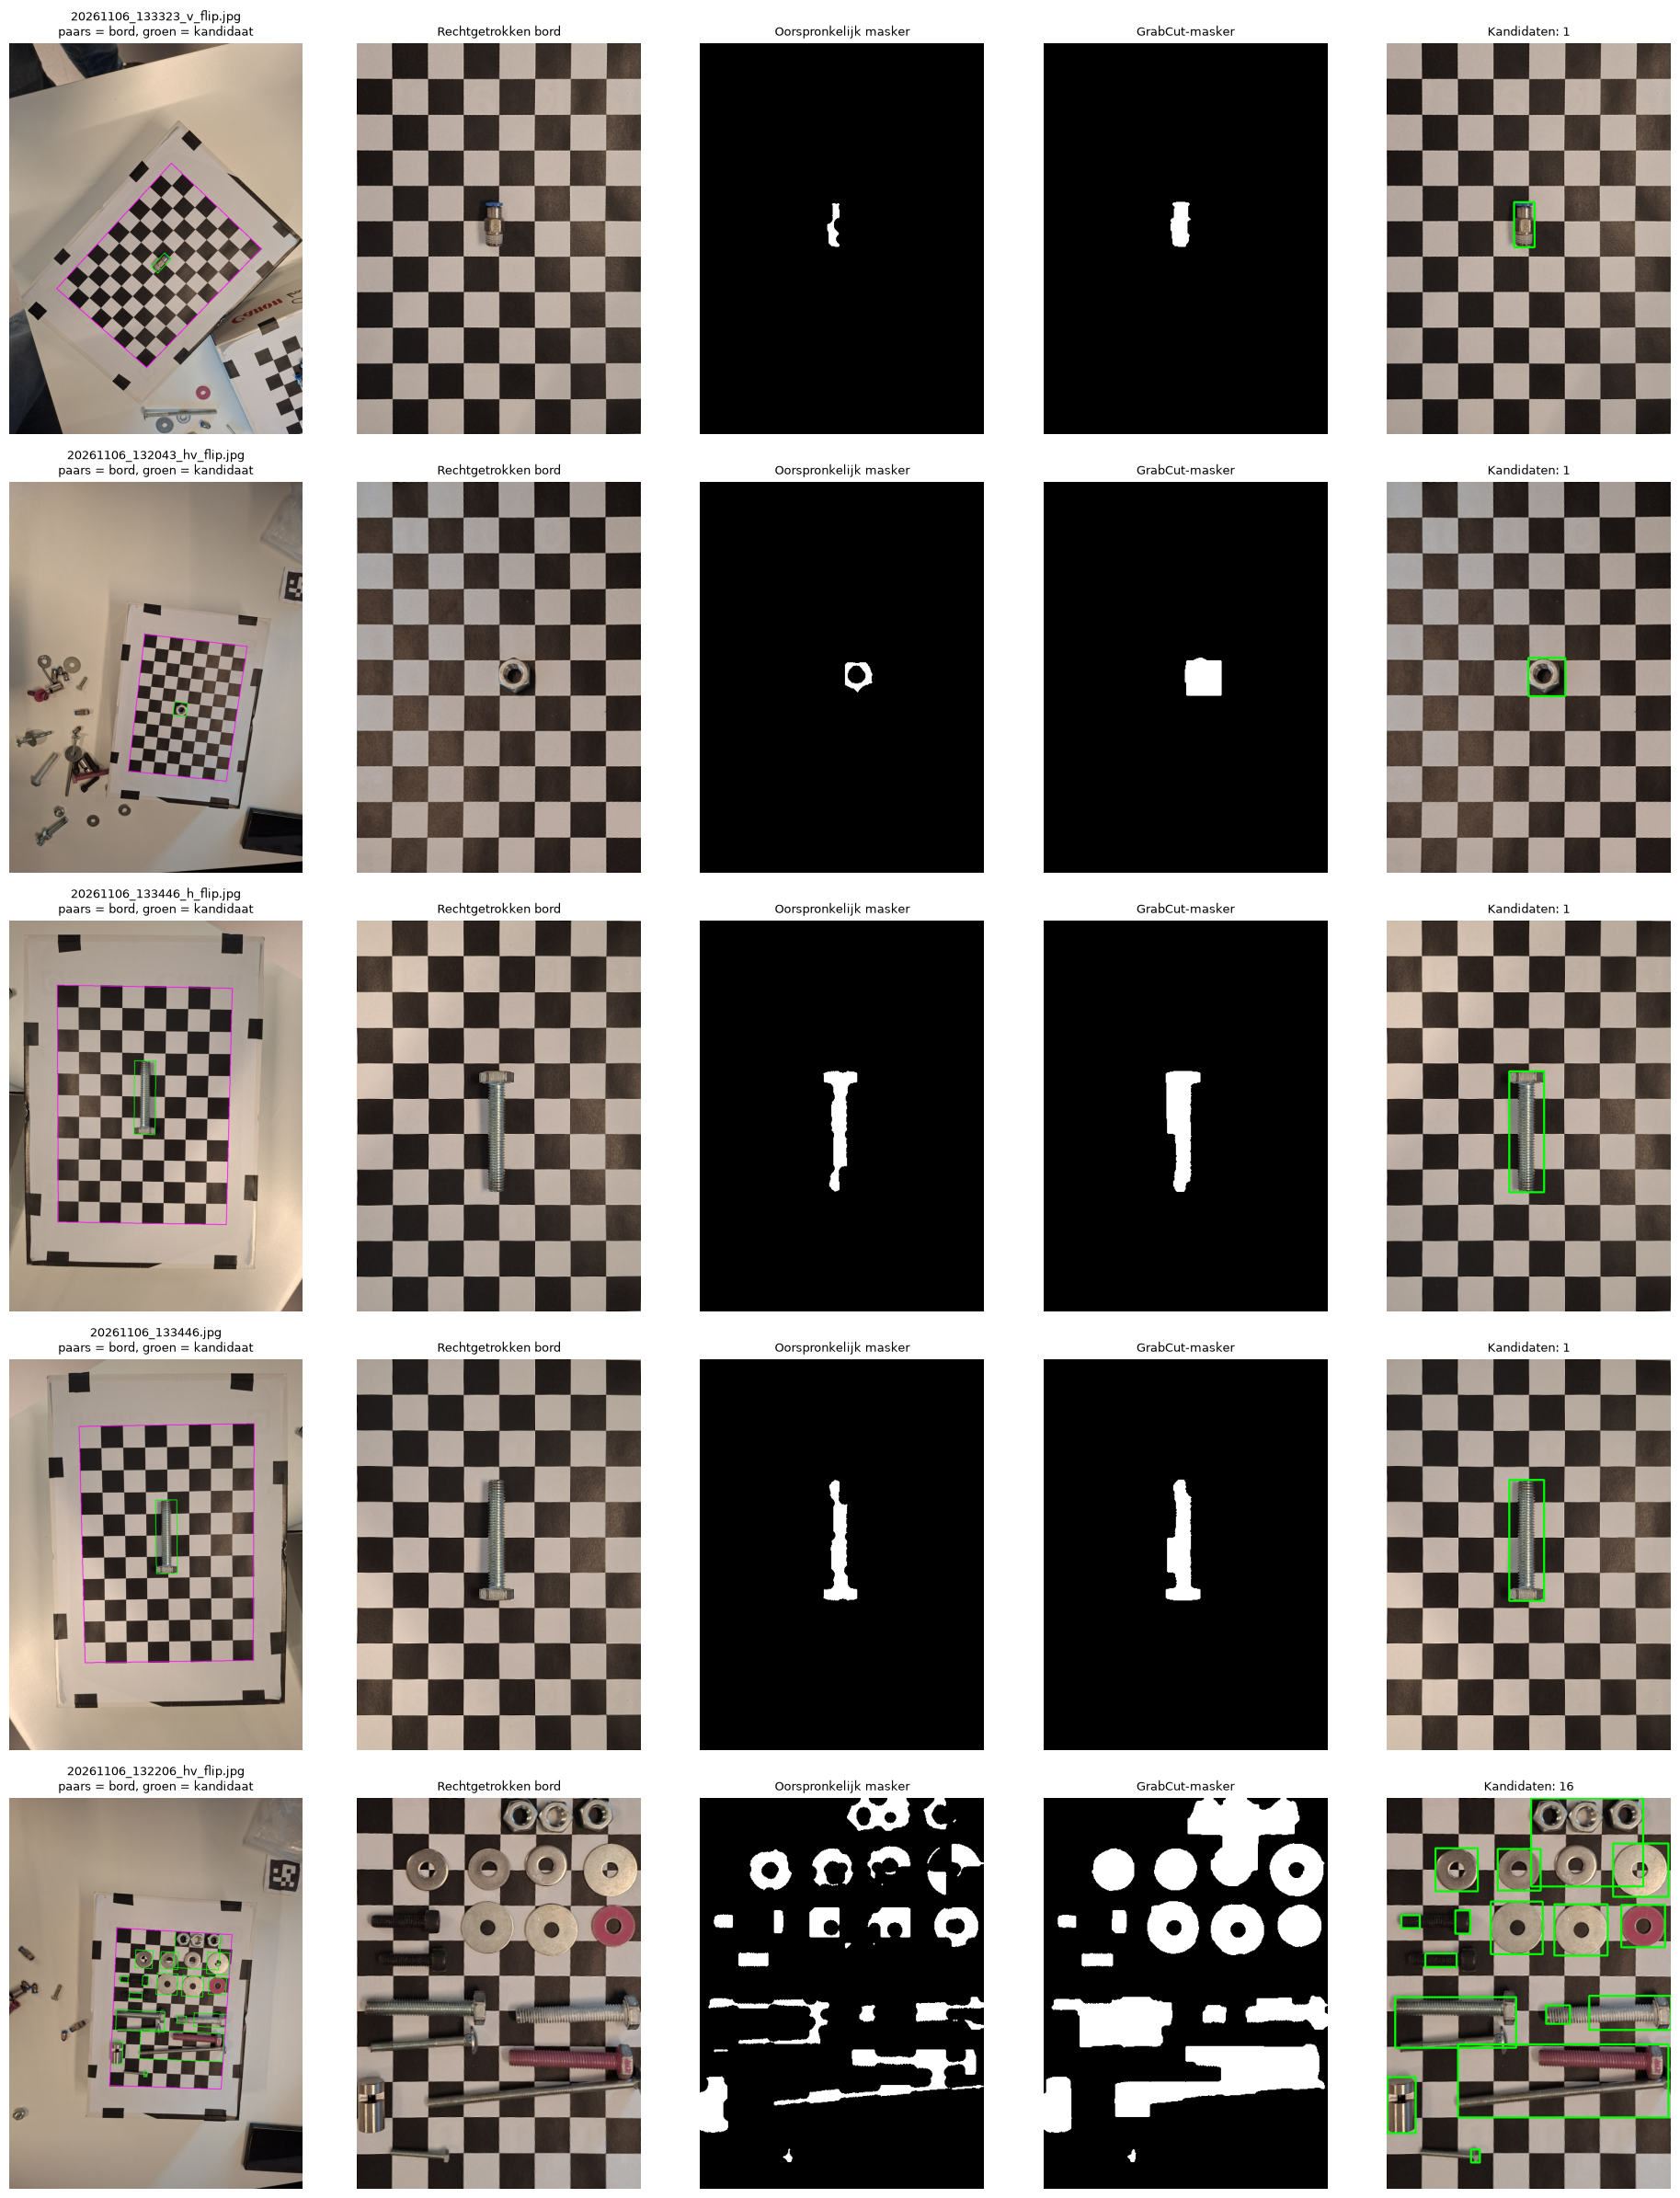

In [48]:
import random
AANTAL_TESTS = 5
MAX_POGINGEN = min(30, len(fotos))
random.seed(42)
selectie = random.sample(fotos, MAX_POGINGEN)

resultaten = []
for pad in selectie:
    if len(resultaten) >= AANTAL_TESTS:
        break
    try:
        d = detecteer_op_bord(lees_foto(pad))
        resultaten.append((pad.name, d))
        print(
    f"{pad.name}: "
    f"{d['methode']} — "
    f"{d['overeenkomst']:.0%} overeenkomst — "
    f"{len(d['detections'])} kandidaten"
)
    except (ValueError, RuntimeError, cv2.error) as fout:
        print(f"{pad.name}: overgeslagen — {fout}")

if resultaten:
    fig, assen = plt.subplots(len(resultaten), 5,
                             figsize=(19, 4.8 * len(resultaten)), squeeze=False)
    for rij, (naam, d) in enumerate(resultaten):
        beelden = [d['origineel'], d['board'], d['mask_zaad'], d['mask'], d['res']]
        titels = [naam + '\npaars = bord, groen = kandidaat', 'Rechtgetrokken bord',
                  'Oorspronkelijk masker', 'GrabCut-masker',
                  f"Kandidaten: {len(d['detections'])}"]
        for j, (beeld, titel) in enumerate(zip(beelden, titels)):
            assen[rij,j].imshow(beeld if j in (2,3) else cv2.cvtColor(beeld, cv2.COLOR_BGR2RGB),
                                cmap='gray' if j in (2,3) else None)
            assen[rij,j].set_title(titel, fontsize=9)
            assen[rij,j].axis('off')
    plt.tight_layout()
    plt.show()

## Wat is er getest?

- Op vier beschikbare testfoto’s kon de oorspronkelijke zwarte-vakjesdetectie bij **twee** foto’s een eerste raster vinden. De drukke foto's blijven lastig.
- Voor de twee geslaagde rasterfits sluit de nieuwe bordregio aan op het zichtbare schaakbord. De nieuwe geometrie beperkt de afwijkingen buiten het bord en de meeste foutieve detecties op de geteste enkelvoudige objectfoto’s.
- **De echte onderdelen zijn nog niet altijd volledig gesegmenteerd:** bijvoorbeeld alleen de kop of een deel van de schacht van een bout. Dat is een bekende beperking, geen succesvolle volledige detectie.
- Positie en oriëntatie moeten pas definitief gerapporteerd worden zodra de objectcontour volledig genoeg is. Een cirkelvormig onderdeel heeft sowieso geen unieke in-vlak-orientatie.

**Volgende test:** vergelijk op 5–10 verschillende foto's het aantal echte objecten dat **volledig** binnen een kandidaatbox ligt, het aantal gemiste objecten en het aantal foutieve boxes. Alle onderdelen buiten de paarse bordgrens mogen buiten beschouwing blijven.

Gekozen afbeelding: 20261106_133446.jpg
Afbeelding: 20261106_133446.jpg
Oorspronkelijke detecties: 1
Gesplitste objectgroepen: 0
Nieuwe detecties: 1


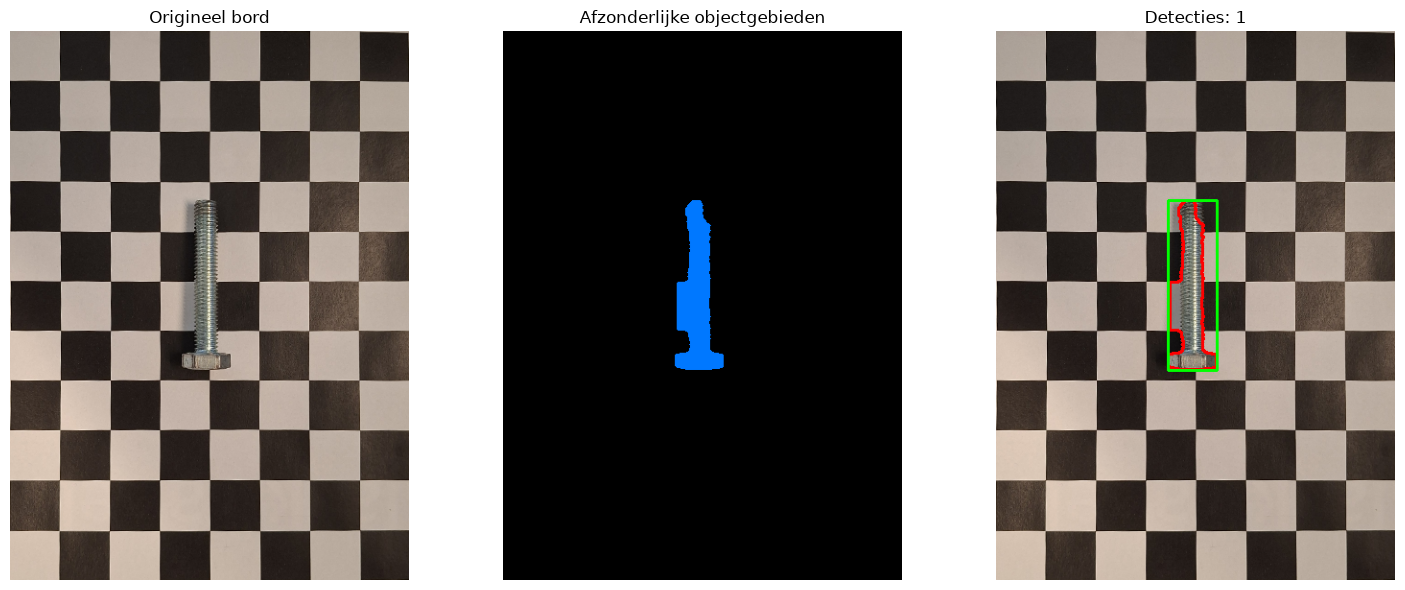

In [49]:

# BLOK 6 — Samengevoegde ronde onderdelen scheiden
# Vereist: detecteer_op_bord(), fotos, lees_foto()
# Geen labels, CNN of YOLO

import cv2
import numpy as np
import matplotlib.pyplot as plt

import random

# Kies een willekeurige afbeelding die in blok 5 is verwerkt
NAAM = random.choice([naam for naam, d in resultaten])

print("Gekozen afbeelding:", NAAM)
CELL = 52

# ==========================================
# 1. AFBEELDING OPHALEN
# ==========================================

d = next(
    (data for naam, data in resultaten if naam == NAAM),
    None
)

if d is None:
    pad = next(
        (p for p in fotos if p.name == NAAM),
        None
    )

    if pad is None:
        raise FileNotFoundError(NAAM)

    d = detecteer_op_bord(lees_foto(pad))

bord = d["board"].copy()
masker = np.uint8(d["mask"] > 0) * 255

h, w = masker.shape
grijs = cv2.cvtColor(bord, cv2.COLOR_BGR2GRAY)

# ==========================================
# 2. VERBONDEN OBJECTEN VINDEN
# ==========================================

aantal, labels, stats, _ = (
    cv2.connectedComponentsWithStats(
        masker, connectivity=8
    )
)

delen = []
gevonden_cirkels = []
gesplitst = 0

for i in range(1, aantal):

    x, y, bw, bh, oppervlakte = map(int, stats[i])

    if oppervlakte < 80 or min(bw, bh) < 8:
        continue

    onderdeel = np.uint8(labels == i) * 255
    verhouding = max(bw, bh) / max(1, min(bw, bh))

    mogelijke_cirkels = []

    # Alleen grotere, compacte objectgroepen onderzoeken.
    # Langwerpige bouten worden niet automatisch gesplitst.
    if (
        oppervlakte > 1.6 * CELL**2
        and bw > 1.2 * CELL
        and bh > 0.8 * CELL
        and verhouding < 2.6
    ):

        marge = 12

        x0 = max(0, x - marge)
        y0 = max(0, y - marge)
        x1 = min(w, x + bw + marge)
        y1 = min(h, y + bh + marge)

        roi = grijs[y0:y1, x0:x1]

        glad = cv2.GaussianBlur(
            roi, (7, 7), 1.2
        )

        cirkels = cv2.HoughCircles(
            glad,
            cv2.HOUGH_GRADIENT,
            dp=1.1,
            minDist=CELL / 2,
            param1=120,
            param2=22,
            minRadius=12,
            maxRadius=int(0.75 * CELL)
        )

        if cirkels is not None:

            for px, py, r in cirkels[0]:

                px = float(px + x0)
                py = float(py + y0)
                r = float(r)

                # Klein gebied rond de cirkel
                xa = max(0, int(px - r - 5))
                xb = min(w, int(px + r + 6))
                ya = max(0, int(py - r - 5))
                yb = min(h, int(py + r + 6))

                Y, X = np.mgrid[ya:yb, xa:xb]

                afstand = np.hypot(
                    X - px, Y - py
                )

                gebied = grijs[ya:yb, xa:xb]

                midden = gebied[
                    afstand <= 0.28 * r
                ]

                ring = gebied[
                    (afstand >= 0.55 * r)
                    & (afstand <= 0.95 * r)
                ]

                if len(midden) < 5 or len(ring) < 10:
                    continue

                # Een ring met een donker gat heeft
                # doorgaans een lichtere buitenrand.
                contrast = float(
                    np.median(ring) - np.median(midden)
                )

                deelmasker = onderdeel[ya:yb, xa:xb]

                binnen = np.count_nonzero(
                    (afstand <= r + 2)
                    & (deelmasker > 0)
                )

                buiten = oppervlakte - binnen

                # Alleen splitsen als de cirkel duidelijk
                # zichtbaar is EN er een tweede deel overblijft.
                if (
                    contrast > 45
                    and binnen > 500
                    and binnen > 0.18 * oppervlakte
                    and buiten > 0.22 * oppervlakte
                ):
                    mogelijke_cirkels.append(
                        (contrast, px, py, r)
                    )

    # ======================================
    # 3. EVENTUEEL SPLITSEN
    # ======================================

    if mogelijke_cirkels:

        contrast, px, py, r = max(
            mogelijke_cirkels,
            key=lambda item: item[0]
        )

        Y, X = np.indices((h, w))

        afstand = np.hypot(X - px, Y - py)

        ringmasker = np.uint8(
            (onderdeel > 0)
            & (afstand <= r + 2)
        ) * 255

        restmasker = np.uint8(
            (onderdeel > 0)
            & (afstand > r + 2)
        ) * 255

        if (
            cv2.countNonZero(ringmasker) > 250
            and cv2.countNonZero(restmasker) > 250
        ):

            delen.extend([ringmasker, restmasker])
            gevonden_cirkels.append((px, py, r))
            gesplitst += 1
            continue

    # Geen betrouwbare splitsing: origineel behouden
    delen.append(onderdeel)


# ==========================================
# 4. NIEUWE DETECTIES TEKENEN
# ==========================================

resultaat = bord.copy()
kleurenmasker = np.zeros_like(bord)

detecties_nieuw = []

kleuren = [
    (255, 120, 0),
    (0, 200, 255),
    (180, 0, 255),
    (0, 255, 100),
    (255, 0, 180)
]

for i, deel in enumerate(delen):

    punten = cv2.findNonZero(deel)

    if punten is None:
        continue

    x, y, bw, bh = cv2.boundingRect(punten)

    if min(bw, bh) < 8:
        continue

    detecties_nieuw.append((x, y, bw, bh))

    kleurenmasker[deel > 0] = kleuren[i % len(kleuren)]

    contouren, _ = cv2.findContours(
        deel,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    # Rode contour
    cv2.drawContours(
        resultaat, contouren, -1,
        (0, 0, 255), 2
    )

    # Groene bounding box
    cv2.rectangle(
        resultaat,
        (x, y),
        (x + bw, y + bh),
        (0, 255, 0), 2
    )

# Blauwe cirkels voor controle
for px, py, r in gevonden_cirkels:
    cv2.circle(
        resultaat,
        (round(px), round(py)),
        round(r),
        (255, 0, 0), 2
    )


# ==========================================
# 5. RESULTATEN TONEN
# ==========================================

print("Afbeelding:", NAAM)
print("Oorspronkelijke detecties:", len(d["detections"]))
print("Gesplitste objectgroepen:", gesplitst)
print("Nieuwe detecties:", len(detecties_nieuw))

fig, assen = plt.subplots(
    1, 3, figsize=(15, 6)
)

beelden = [
    bord,
    kleurenmasker,
    resultaat
]

titels = [
    "Origineel bord",
    "Afzonderlijke objectgebieden",
    f"Detecties: {len(detecties_nieuw)}"
]

for ax, beeld, titel in zip(assen, beelden, titels):
    ax.imshow(
        cv2.cvtColor(beeld, cv2.COLOR_BGR2RGB)
    )
    ax.set_title(titel)
    ax.axis("off")

plt.tight_layout()
plt.show()


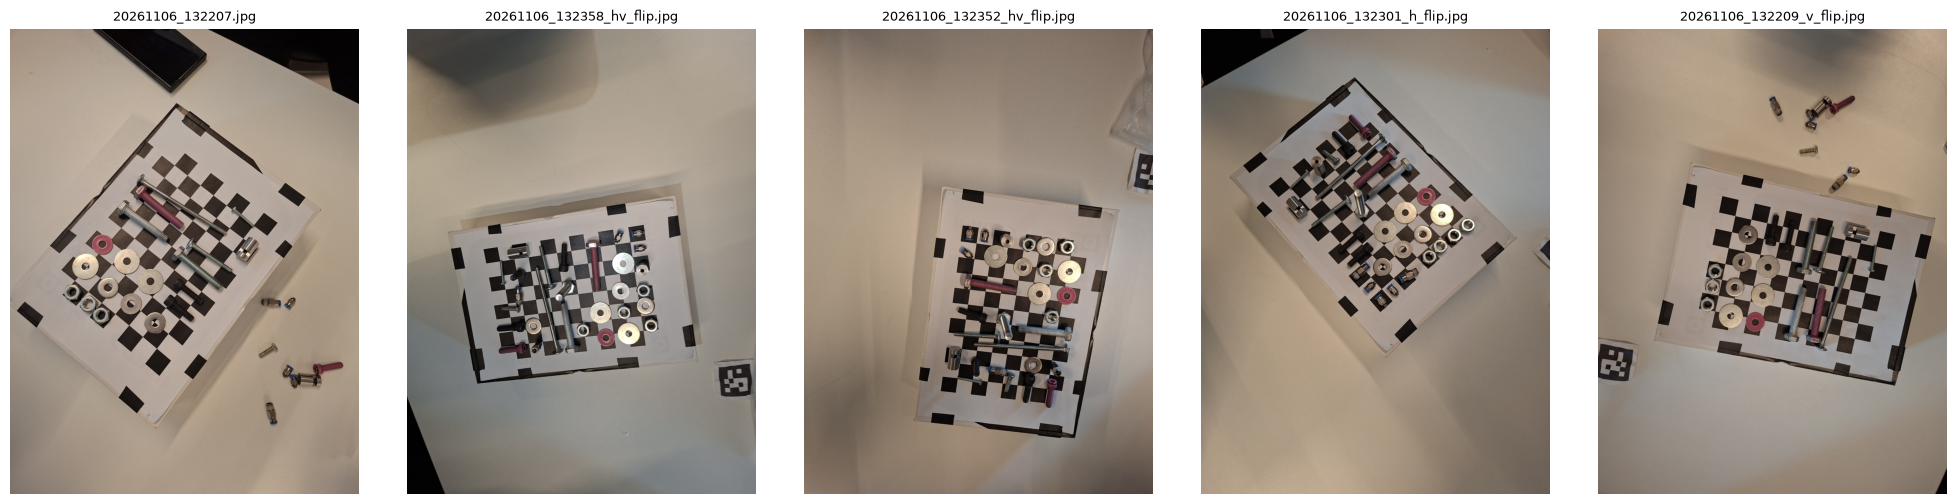

In [50]:
# Toon afbeeldingen waarbij de schaakborddetectie mislukt

namen = [
    "20261106_132207.jpg",
    "20261106_132358_hv_flip.jpg",
    "20261106_132352_hv_flip.jpg",
    "20261106_132301_h_flip.jpg",
    "20261106_132209_v_flip.jpg"
]

fig, assen = plt.subplots(1, 5, figsize=(20, 5))

for ax, naam in zip(assen, namen):
    pad = next(p for p in fotos if p.name == naam)
    foto = lees_foto(pad)

    ax.imshow(cv2.cvtColor(foto, cv2.COLOR_BGR2RGB))
    ax.set_title(naam, fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()